In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("drug200.csv")

In [6]:
data.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [8]:
data.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


In [9]:
data.tail()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX
199,40,F,LOW,NORMAL,11.349,drugX


In [10]:
data.shape

(200, 6)

In [11]:
data.size

1200

In [12]:
data.isnull().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [14]:
for col in data:
    print(f'{col} : {data[col].unique()}')

Age : [23 47 28 61 22 49 41 60 43 34 74 50 16 69 32 57 63 48 33 31 39 45 18 65
 53 46 15 73 58 66 37 68 67 62 24 26 40 38 29 17 54 70 36 19 64 59 51 42
 56 20 72 35 52 55 30 21 25]
Sex : ['F' 'M']
BP : ['HIGH' 'LOW' 'NORMAL']
Cholesterol : ['HIGH' 'NORMAL']
Na_to_K : [25.355 13.093 10.114  7.798 18.043  8.607 16.275 11.037 15.171 19.368
 11.767 19.199 15.376 20.942 12.703 15.516 11.455 13.972  7.298 25.974
 19.128 25.917 30.568 15.036 33.486 18.809 30.366  9.381 22.697 17.951
  8.75   9.567 11.014 31.876 14.133  7.285  9.445 13.938  9.709  9.084
 19.221 14.239 15.79  12.26  12.295  8.107 13.091 10.291 31.686 19.796
 19.416 10.898 27.183 18.457 10.189 14.16  11.34  27.826 10.091 18.703
 29.875  9.475 20.693  8.37  13.303 27.05  12.856 10.832 24.658 24.276
 13.967 19.675 10.605 22.905 17.069 20.909 11.198 19.161 13.313 10.84
 13.934  7.761  9.712 11.326 10.067 13.935 13.597 15.478 23.091 17.211
 16.594 15.156 29.45  29.271 15.015 11.424 38.247 25.395 35.639 16.725
 11.871 12.854 13.127  

In [15]:
data.replace({'Sex' : {'F' : 1, 'M' : 0}}, inplace = True)

C:\Users\kriti\AppData\Local\Temp\ipykernel_8120\3652514604.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data.replace({'Sex' : {'F' : 1, 'M' : 0}}, inplace = True)


In [16]:
data['Sex'].unique()

array([1, 0])

In [17]:
bp = pd.get_dummies(data['BP'])
data.drop(['BP'], axis = 1, inplace = True)
data = pd.concat([data, bp], axis = 1)
data.head()

,Age,Sex,Cholesterol,Na_to_K,Drug,HIGH,LOW,NORMAL
0,23,1,HIGH,25.355,drugY,True,False,False
1,47,0,HIGH,13.093,drugC,False,True,False
2,47,0,HIGH,10.114,drugC,False,True,False
3,28,1,HIGH,7.798,drugX,False,False,True
4,61,1,HIGH,18.043,drugY,False,True,False


In [18]:
from sklearn.preprocessing import LabelEncoder
obj = LabelEncoder()
data.Cholesterol = obj.fit_transform(data.Cholesterol)
data.Cholesterol.unique()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    int64  
 2   Cholesterol  200 non-null    int64  
 3   Na_to_K      200 non-null    float64
 4   Drug         200 non-null    object 
 5   HIGH         200 non-null    bool   
 6   LOW          200 non-null    bool   
 7   NORMAL       200 non-null    bool   
dtypes: bool(3), float64(1), int64(3), object(1)
memory usage: 8.5+ KB


In [19]:
data.head()

,Age,Sex,Cholesterol,Na_to_K,Drug,HIGH,LOW,NORMAL
0,23,1,0,25.355,drugY,True,False,False
1,47,0,0,13.093,drugC,False,True,False
2,47,0,0,10.114,drugC,False,True,False
3,28,1,0,7.798,drugX,False,False,True
4,61,1,0,18.043,drugY,False,True,False


<Axes: >

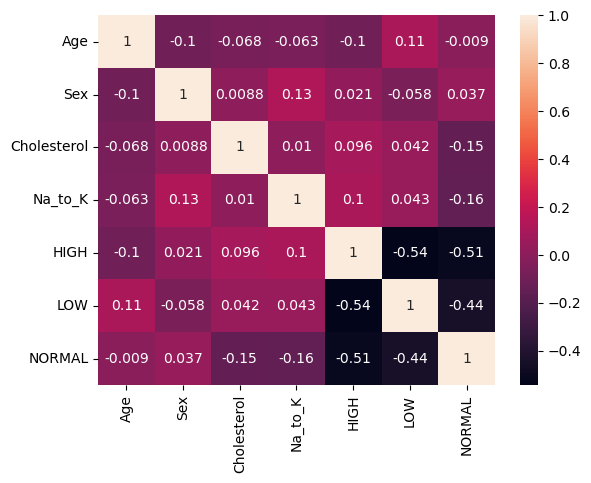

In [23]:
sns.heatmap(data.corr(numeric_only = True), annot = True)

In [20]:
X = data.drop("Drug", axis = 1)
Y = data['Drug']

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.4, random_state = 48)
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(120, 7)
(80, 7)
(120,)
(80,)


In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report, confusion_matrix

In [25]:
models = {
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier()
}

Decision Tree
              precision    recall  f1-score   support

       drugA       0.89      1.00      0.94         8
       drugB       1.00      0.90      0.95        10
       drugC       1.00      1.00      1.00         5
       drugX       1.00      0.95      0.97        19
       drugY       0.97      1.00      0.99        38

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



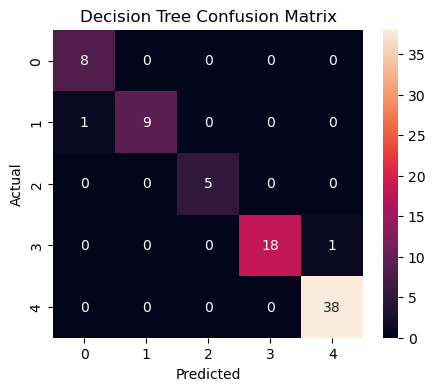

Random Forest
              precision    recall  f1-score   support

       drugA       0.89      1.00      0.94         8
       drugB       1.00      0.90      0.95        10
       drugC       1.00      1.00      1.00         5
       drugX       1.00      0.95      0.97        19
       drugY       0.97      1.00      0.99        38

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.98      0.97      0.97        80



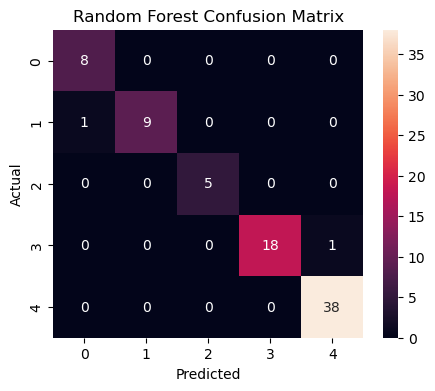

In [ ]:
for name, model in models.items():
    model.fit(X_train, Y_train)

    Y_pred = model.predict(X_test)

    print(name)

    print(classification_report(Y_test, Y_pred))
    conf = confusion_matrix(Y_test, Y_pred)

    plt.figure(figsize=(5, 4)) 
    sns.heatmap(conf, annot=True, fmt="d")

    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [28]:
import pickle

for name, model in models.items():
    model.fit(X_train, Y_train)

    filename = name.lower().replace(" ", "_") + ".pkl"

    with open(filename, "wb") as file:
        pickle.dump(model, file)